<a href="https://colab.research.google.com/github/A-ghori/sklearn/blob/recovery/Gradient_Descent_Scratch2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import cross_val_score


X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, random_state=42)

print(X.shape)
print(y.shape)

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X,y)

scores = cross_val_score(
    lr,
    X,
    y,
    cv=4,
    scoring="r2"
)
print(lr.coef_)
print(lr.intercept_)
print(scores)
print(scores.mean())

(100, 1)
(100,)
[41.74110031]
0.0
[1. 1. 1. 1.]
1.0


In [12]:
class GDRegression:
  def __init__(self,m, b, lr, epochs):
    self.m = m
    self.b = b

    self.lr = lr
    self.epochs = epochs

  def fit(self, X, y):

    self.bias_history = []
    self.loss_history = []

    # calculate the b using GD
    for epoch in range(self.epochs):
      loss_slope_b = -2 * np.sum(y - self.m * X.ravel() - self.b)
      loss_slope_m = -2 * np.sum((y - self.m * X.ravel() -self.b) * X.ravel())

      #update the m
      self.m = self.m - loss_slope_m * self.lr
      # update the b
      self.b = self.b - loss_slope_b * self.lr

      # calculate predictions with updates b
      y_pred = self.m * X.ravel() + self.b

      # calculate loss
      loss = np.sum((y - y_pred) ** 2)

      self.bias_history.append(self.b)
      self.loss_history.append(loss)

      print(f"Epoch: {epoch} Loss: {loss}")
      print("Bias is ",self.b)
      print("Slope is ",self.m)

    print(self.b , self.m)






In [16]:
gd = GDRegression(
    m=41.74110031,
    b=0.0,
    lr=0.001,
    epochs=100
)

print(gd.fit(X, y))

Epoch: 0 Loss: 1.3634184757202468e-15
Bias is  -1.0131065925067518e-10
Slope is  41.741100310807106
Epoch: 1 Loss: 9.47043432487662e-16
Bias is  -1.6559612648903158e-10
Slope is  41.74110031147856
Epoch: 2 Loss: 6.595651423281045e-16
Bias is  -2.0307880296055465e-10
Slope is  41.74110031203758
Epoch: 3 Loss: 4.604660968694083e-16
Bias is  -2.214545262329005e-10
Slope is  41.74110031250333
Epoch: 4 Loss: 3.221815721458119e-16
Bias is  -2.2648182167630547e-10
Slope is  41.741100312891625
Epoch: 5 Loss: 2.2587877612244677e-16
Bias is  -2.2243895623576653e-10
Slope is  41.741100313215576
Epoch: 6 Loss: 1.5865081141127628e-16
Bias is  -2.12476528834241e-10
Slope is  41.74110031348601
Epoch: 7 Loss: 1.116162251394519e-16
Bias is  -1.9888989130440825e-10
Slope is  41.7411003137119
Epoch: 8 Loss: 7.864157606380117e-17
Bias is  -1.8332895175122338e-10
Slope is  41.741100313900695
Epoch: 9 Loss: 5.548221102073768e-17
Bias is  -1.6695904215478544e-10
Slope is  41.74110031405858
Epoch: 10 Loss: 3.

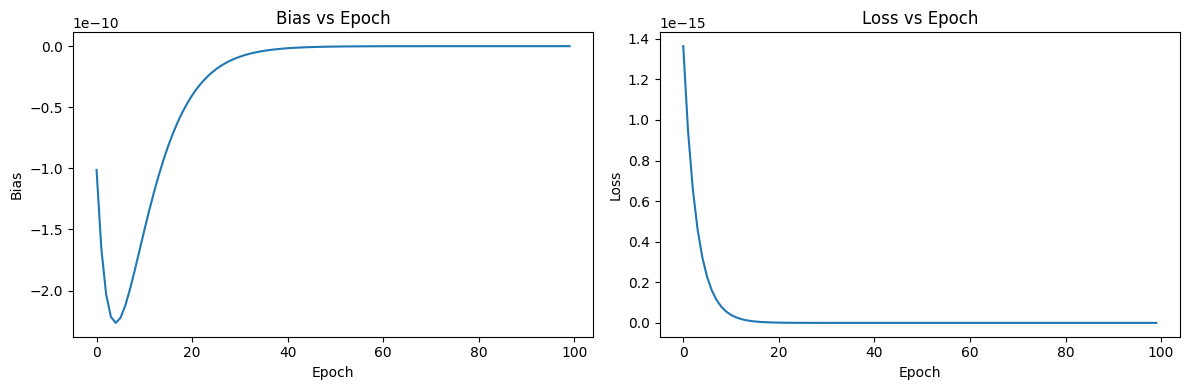

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Bias graph
ax[0].plot(gd.bias_history)
ax[0].set_title("Bias vs Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Bias")

# Loss graph
ax[1].plot(gd.loss_history)
ax[1].set_title("Loss vs Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()